In [ ]:
from google.colab import files

uploaded = files.upload()

Saving simple_cyber_activity.csv to simple_cyber_activity.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Set random seeds
np.random.seed(42)
tf.random.set_seed(42)

# Load dataset
df = pd.read_csv('simple_cyber_activity.csv')

# Display first five rows
print("First 5 rows of dataset:")
display(df.head())

# Display dataset information
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

# Select four numerical features
features = [
    'failed_logins',
    'login_hour',
    'new_device',
    'data_transfer_mb'
]

# Separate input and output
X = df[features]
y = df['label']

# Display class counts
print("\nClass Distribution:")
print(y.value_counts())

# Split dataset into 75% training and 25% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Normalize the data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nTraining shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nDataset preparation completed successfully!")

First 5 rows of dataset:


,record_id,failed_logins,login_hour,new_device,data_transfer_mb,label
0,1,4,1,0,164.9,1
1,2,3,3,1,250.6,1
2,3,3,10,0,145.1,0
3,4,2,11,0,397.8,0
4,5,1,3,0,409.3,0



Dataset shape: (100, 6)

Column names: ['record_id', 'failed_logins', 'login_hour', 'new_device', 'data_transfer_mb', 'label']

Class Distribution:
label
0    75
1    25
Name: count, dtype: int64

Training shape: (75, 4)
Testing shape: (25, 4)

Dataset preparation completed successfully!


In [ ]:
# Create Sequential Neural Network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(4, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the model
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=8,
    verbose=1
)

# Display final accuracy
print("\nFinal Training Accuracy:",
      round(history.history['accuracy'][-1] * 100, 2), "%")

print("Final Validation Accuracy:",
      round(history.history['val_accuracy'][-1] * 100, 2), "%")

print("\nNeural Network Training Completed!")

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.4000 - loss: 0.7352 - val_accuracy: 0.6667 - val_loss: 0.6568
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4167 - loss: 0.7249 - val_accuracy: 0.7333 - val_loss: 0.6481
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4500 - loss: 0.7154 - val_accuracy: 0.8000 - val_loss: 0.6396
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4833 - loss: 0.7063 - val_accuracy: 0.8000 - val_loss: 0.6312
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5500 - loss: 0.6974 - val_accuracy: 0.9333 - val_loss: 0.6228
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5500 - loss: 0.6888 - val_accuracy: 0.9333 - val_loss: 0.6144
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5667 - loss: 0.6801 - val_accuracy: 0.9333 - val_loss: 0.6060
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5667 - loss: 0.6716 - val_accuracy: 0.9333 - val_loss: 0.5974


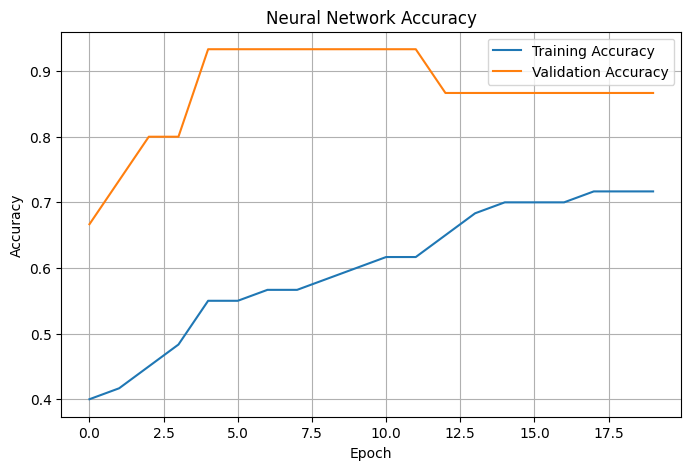

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Neural Network Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

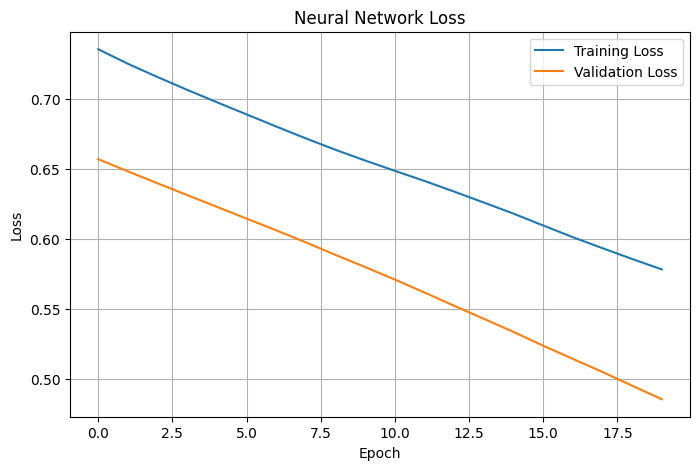

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('Neural Network Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test Accuracy:",
      round(test_accuracy * 100, 2), "%")

print("Test Loss:",
      round(test_loss, 4))

Test Accuracy: 76.0 %
Test Loss: 0.524


In [ ]:
# Create three new cyber activity records
new_records = pd.DataFrame([
    {
        'failed_logins': 0,
        'login_hour': 11,
        'new_device': 0,
        'data_transfer_mb': 35
    },
    {
        'failed_logins': 7,
        'login_hour': 1,
        'new_device': 1,
        'data_transfer_mb': 250
    },
    {
        'failed_logins': 2,
        'login_hour': 23,
        'new_device': 1,
        'data_transfer_mb': 850
    }
])

# Normalize new records using the existing scaler
new_scaled = scaler.transform(new_records[features])

# Predict probabilities
probabilities = model.predict(
    new_scaled,
    verbose=0
).flatten()

# Convert probabilities into labels
new_records['nn_probability'] = probabilities.round(3)

new_records['nn_prediction'] = np.where(
    probabilities >= 0.50,
    'Attack',
    'Normal'
)

print("Neural Network Predictions:")
display(new_records)

Neural Network Predictions:


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction
0,0,11,0,35,0.305,Normal
1,7,1,1,250,0.472,Normal
2,2,23,1,850,0.472,Normal


In [ ]:
# Create Decision Tree model
tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Train Decision Tree on the same training data
tree.fit(X_train, y_train)

# Predict testing data
tree_pred = tree.predict(X_test)

# Calculate Decision Tree accuracy
tree_accuracy = accuracy_score(y_test, tree_pred)

# Predict new records
tree_new_predictions = tree.predict(new_records[features])

new_records['tree_prediction'] = np.where(
    tree_new_predictions == 1,
    'Attack',
    'Normal'
)

# Display comparison
print("Neural Network Accuracy:",
      round(test_accuracy * 100, 2), "%")

print("Decision Tree Accuracy:",
      round(tree_accuracy * 100, 2), "%")

print("\nFinal Prediction Comparison:")
display(new_records)

Neural Network Accuracy: 76.0 %
Decision Tree Accuracy: 88.0 %

Final Prediction Comparison:


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.305,Normal,Normal
1,7,1,1,250,0.472,Normal,Attack
2,2,23,1,850,0.472,Normal,Attack


,Model,Accuracy (%)
0,Neural Network,76.0
1,Decision Tree,88.0


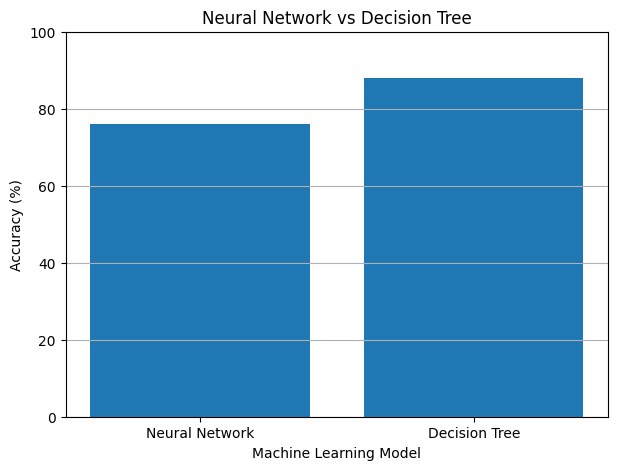

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Neural Network', 'Decision Tree'],
    'Accuracy (%)': [
        round(test_accuracy * 100, 2),
        round(tree_accuracy * 100, 2)
    ]
})

display(comparison)

plt.figure(figsize=(7, 5))

plt.bar(
    comparison['Model'],
    comparison['Accuracy (%)']
)

plt.title('Neural Network vs Decision Tree')
plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.grid(axis='y')

plt.show()

In [ ]:
print("=" * 55)
print("LAB 3 - FINAL RESULT")
print("=" * 55)

print(f"Dataset Records: {len(df)}")
print(f"Training Records: {len(X_train)}")
print(f"Testing Records: {len(X_test)}")

print("\nNEURAL NETWORK RESULTS")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

print("\nDECISION TREE RESULTS")
print(f"Decision Tree Accuracy: {tree_accuracy * 100:.2f}%")

print("\nMODEL COMPARISON")

if test_accuracy > tree_accuracy:
    print("Neural Network performed better.")
elif tree_accuracy > test_accuracy:
    print("Decision Tree performed better.")
else:
    print("Both models achieved equal accuracy.")

print("\nNEW RECORD PREDICTIONS")
display(new_records)

print("\nCONCLUSION")
print(
    "The neural network was successfully trained to classify "
    "cyber activity into Normal and Attack categories. "
    "The model was evaluated using accuracy and loss, and its "
    "performance was compared with a Decision Tree classifier. "
    "Three new cyber activity records were also tested."
)

print("\nLAB 3 COMPLETED SUCCESSFULLY!")
print("=" * 55)

LAB 3 - FINAL RESULT
Dataset Records: 100
Training Records: 75
Testing Records: 25

NEURAL NETWORK RESULTS
Test Accuracy: 76.00%
Test Loss: 0.5240

DECISION TREE RESULTS
Decision Tree Accuracy: 88.00%

MODEL COMPARISON
Decision Tree performed better.

NEW RECORD PREDICTIONS


,failed_logins,login_hour,new_device,data_transfer_mb,nn_probability,nn_prediction,tree_prediction
0,0,11,0,35,0.305,Normal,Normal
1,7,1,1,250,0.472,Normal,Attack
2,2,23,1,850,0.472,Normal,Attack



CONCLUSION
The neural network was successfully trained to classify cyber activity into Normal and Attack categories. The model was evaluated using accuracy and loss, and its performance was compared with a Decision Tree classifier. Three new cyber activity records were also tested.

LAB 3 COMPLETED SUCCESSFULLY!
